# Chest X-Ray Pneumonia — Data Exploration

We explore the downloaded NORMAL/PNEUMONIA images before feature engineering and model training. Each numbered section explains one task and shows its output, following the organization of the supplied [EDA reference notebook](https://github.com/tejuuu-7774/Inventory-demand-forecasting/blob/main/Notebooks/01_data_exploration.ipynb).

Run notebooks **01 → 02 → 03**. In Colab, upload all three notebooks and place the extracted image folder in Google Drive at `MyDrive/chest_xray`. All notebooks use the same Drive project folder. Saved local outputs can be viewed immediately; rerunning in Colab needs the dataset. This notebook performs EDA only; training is in notebook 03.

## 1. Import the libraries

Pandas builds an image metadata table, NumPy summarizes pixels, Pillow reads images, and Matplotlib creates plots.

In [1]:
import sys, json, hashlib, re, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Image as NotebookImage
SEED = 42
CLASSES = {'NORMAL': 0, 'PNEUMONIA': 1}
IN_COLAB = importlib.util.find_spec('google.colab') is not None
print('Environment:', 'Google Colab' if IN_COLAB else 'Local Python')


def show_plot(name):
    path = FIGURE_DIR / name
    plt.gcf().text(.01, .005, 'Source: local Kaggle chest_xray download; supplied splits; exploratory summaries', fontsize=8)
    plt.tight_layout(rect=(0,.025,1,1))
    plt.savefig(path, dpi=140)
    plt.close()
    display(NotebookImage(filename=str(path)))

Environment: Local Python


## 2. Find the project and dataset folders

We select one train/val/test tree. The nested second copy and macOS resource files must not be counted twice.

In [2]:
# Use the SAME PROJECT_ROOT in all three notebooks.
# Colab: put the extracted images under MyDrive/chest_xray before running.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Chest-Xray-Pneumonia-ML')
    DATA_ROOT = Path('/content/drive/MyDrive/chest_xray')
else:
    PROJECT_ROOT = Path.cwd()
    if PROJECT_ROOT.name == 'Notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
    DATA_ROOT = Path.home() / 'Downloads/chest_xray'
OUTPUT = PROJECT_ROOT
for folder in ('Datasets/processed','results','report/figures','models'):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
PROCESSED_DIR = PROJECT_ROOT / 'Datasets/processed'
FIGURE_DIR = PROJECT_ROOT / 'report/figures'
print('Project folder:', PROJECT_ROOT)
print('Raw data folder:', DATA_ROOT)

print('Dataset exists:', DATA_ROOT.exists())

Project folder: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML
Raw data folder: /Users/ravichandrashinde/Downloads/chest_xray
Dataset exists: True


## 3. Load and inspect every image

The helper decodes images and records dimensions, intensity, pixel hashes and filename proxies. Its grouping logic also prepares an auditable exclusion policy for later notebooks. No predictor is trained here.

In [3]:
def save_json(value, path):
    Path(path).write_text(json.dumps(value, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)))


def resolve_root(root):
    root = Path(root).expanduser().resolve()
    candidates = [root, root / 'chest_xray', root / 'chest_xray' / 'chest_xray']
    for candidate in candidates:
        if all((candidate / s / c).is_dir() for s in ('train', 'val', 'test') for c in CLASSES):
            return candidate
    raise FileNotFoundError(f'Expected train/val/test with NORMAL/PNEUMONIA beneath {root}')


def patient_proxy(name):
    """Filename-derived proxy, NOT a verified patient identifier."""
    stem = Path(name).stem
    m = re.match(r'(person\d+)_', stem)
    if m:
        return m.group(1)
    m = re.match(r'((?:NORMAL2-)?IM-\d+)', stem)
    return m.group(1) if m else 'unknown:' + stem


def audit(root, out):
    root = resolve_root(root)
    records, corrupt = [], []
    for split in ('train', 'val', 'test'):
        for label, target in CLASSES.items():
            for path in sorted((root / split / label).iterdir()):
                if path.suffix.lower() not in {'.jpeg', '.jpg', '.png'} or path.name.startswith('._'):
                    continue
                try:
                    with Image.open(path) as im:
                        im.load()
                        gray = im.convert('L')
                        arr = np.asarray(gray)
                        # Dimensions are part of the pixel fingerprint; compression bytes are not.
                        digest = hashlib.sha256(str(arr.shape).encode() + arr.tobytes()).hexdigest()
                        records.append(dict(path=str(path.relative_to(root)), split=split, label=label,
                            target=target, width=im.width, height=im.height, mode=im.mode,
                            mean_intensity=float(arr.mean()), std_intensity=float(arr.std()),
                            dark_fraction=float((arr <= 5).mean()), bright_fraction=float((arr >= 250).mean()),
                            pixel_hash=digest, patient_proxy=patient_proxy(path.name)))
                except (OSError, ValueError) as exc:
                    corrupt.append({'path': str(path.relative_to(root)), 'error': str(exc)})
    df = pd.DataFrame(records)
    if df.empty:
        raise ValueError('No readable images found')
    # Connected components bind same patient proxies AND identical decoded images.
    parent = list(range(len(df)))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for column in ('patient_proxy', 'pixel_hash'):
        for ids in df.groupby(column).indices.values():
            first = int(ids[0])
            for idx in ids[1:]:
                parent[find(int(idx))] = find(first)
    df['group'] = [f'g{find(i)}' for i in range(len(df))]
    conflict_hashes = set(df.groupby('pixel_hash').target.nunique().loc[lambda x: x > 1].index)
    test_groups = set(df.loc[df.split == 'test', 'group'])
    df['excluded_reason'] = ''
    df.loc[(df.split != 'test') & df.group.isin(test_groups), 'excluded_reason'] = 'group_overlap_with_test'
    df.loc[df.pixel_hash.isin(conflict_hashes), 'excluded_reason'] = 'conflicting_duplicate_label'
    eligible = df.excluded_reason.eq('')
    duplicate = df.loc[eligible].duplicated('pixel_hash', keep='first')
    df.loc[duplicate.index[duplicate], 'excluded_reason'] = 'exact_pixel_duplicate'
    df['partition'] = np.where(df.split == 'test', 'test', 'development')
    df.loc[df.excluded_reason.ne(''), 'partition'] = 'excluded'
    df.to_csv(out / 'Datasets/processed/manifest.csv', index=False)
    pd.DataFrame(corrupt, columns=['path', 'error']).to_csv(out / 'results/corrupt_images.csv', index=False)
    summary = dict(root=str(root), readable_images=len(df), corrupt_images=len(corrupt),
        original_counts=df.groupby(['split','label']).size().to_dict(),
        duplicate_pixel_images=int(df.duplicated('pixel_hash').sum()),
        cross_split_hash_groups=int((df.groupby('pixel_hash').split.nunique() > 1).sum()),
        conflicting_pixel_hashes=len(conflict_hashes),
        exclusions=df.loc[df.partition == 'excluded', 'excluded_reason'].value_counts().to_dict(),
        retained_counts=df.loc[df.partition != 'excluded'].groupby(['partition','label']).size().to_dict(),
        patient_identity_caveat='Filename proxies only; true patient disjointness cannot be certified. Near duplicates are not fully detected.')
    # JSON keys cannot be tuples.
    for key in ('original_counts','retained_counts'):
        summary[key] = {'/'.join(k):v for k,v in summary[key].items()}
    save_json(summary, out / 'results/dataset_audit.json')
    return root, df, summary



root, images, audit_summary = audit(DATA_ROOT, OUTPUT)
print('Readable image table:', images.shape)
print('Corrupt images:', audit_summary['corrupt_images'])

Readable image table: (5856, 16)
Corrupt images: 0


## 4. Identify the available columns

Each row is one image. The label comes from its folder. The filename-derived group is an imperfect patient proxy and must never be used as an input feature.

In [4]:
display(pd.DataFrame({'column': images.columns, 'dtype': images.dtypes.astype(str).values}))

,column,dtype
0,path,str
1,split,str
2,label,str
3,target,int64
4,width,int64
5,height,int64
6,mode,str
7,mean_intensity,float64
8,std_intensity,float64
9,dark_fraction,float64


## 5. Preview the image table

Inspect several records before aggregating. Paths are relative to the canonical dataset root.

In [5]:
display(images[['path','split','label','width','height','mode','mean_intensity','patient_proxy']].head(8))

,path,split,label,width,height,mode,mean_intensity,patient_proxy
0,train/NORMAL/IM-0115-0001.jpeg,train,NORMAL,2090,1858,L,128.907478,IM-0115
1,train/NORMAL/IM-0117-0001.jpeg,train,NORMAL,1422,1152,L,100.650624,IM-0117
2,train/NORMAL/IM-0119-0001.jpeg,train,NORMAL,1810,1434,L,121.971530,IM-0119
3,train/NORMAL/IM-0122-0001.jpeg,train,NORMAL,1618,1279,L,132.986188,IM-0122
4,train/NORMAL/IM-0125-0001.jpeg,train,NORMAL,1600,1125,L,106.224797,IM-0125
5,train/NORMAL/IM-0127-0001.jpeg,train,NORMAL,1974,1306,L,130.381746,IM-0127
6,train/NORMAL/IM-0128-0001.jpeg,train,NORMAL,1528,1013,L,97.196314,IM-0128
7,train/NORMAL/IM-0129-0001.jpeg,train,NORMAL,1384,1167,L,115.637723,IM-0129


## 6. Check the sizes of the dataset splits

Count images in each class and supplied split. The validation folder may be too small for reliable model selection.

In [6]:
counts = pd.crosstab(images.split, images.label).reindex(['train','val','test'])
display(counts.assign(total=counts.sum(axis=1)))
print('Total readable images:', len(images))

Total readable images: 5856


label,NORMAL,PNEUMONIA,total
split,,,
train,1341,3875,5216
val,8,8,16
test,234,390,624


## 7. Check duplicate images

Equal decoded grayscale pixels, including shape, define exact duplicates. Different JPEG bytes can decode to the same image. Near duplicates are not fully detected.

In [7]:
print('Repeated pixel images:', images.duplicated('pixel_hash').sum())
print('Label-conflicting hashes:', audit_summary['conflicting_pixel_hashes'])
display(images[images.duplicated('pixel_hash', keep=False)][['path','split','label','pixel_hash']].head(10))

Repeated pixel images: 32
Label-conflicting hashes: 0


,path,split,label,pixel_hash
753,train/NORMAL/NORMAL2-IM-0587-0001-0001.jpeg,train,NORMAL,5d614b05e2609f3e4889f5ac0c9688ed0cfc4ce5ec96e3...
754,train/NORMAL/NORMAL2-IM-0587-0001-0002.jpeg,train,NORMAL,5d614b05e2609f3e4889f5ac0c9688ed0cfc4ce5ec96e3...
1633,train/PNEUMONIA/person1159_virus_1944.jpeg,train,PNEUMONIA,6dfc9456499ee64693177339885252f84a475bfb92c639...
1634,train/PNEUMONIA/person1159_virus_1945.jpeg,train,PNEUMONIA,6dfc9456499ee64693177339885252f84a475bfb92c639...
1822,train/PNEUMONIA/person124_virus_246.jpeg,train,PNEUMONIA,f0c7dc20e37a7eaceba3f2aefa02a603539ec6aa96e0c3...
1823,train/PNEUMONIA/person124_virus_247.jpeg,train,PNEUMONIA,f0c7dc20e37a7eaceba3f2aefa02a603539ec6aa96e0c3...
1846,train/PNEUMONIA/person1261_virus_2147.jpeg,train,PNEUMONIA,b6e90a2ed025c5283d8affd01ea60ed697a6975c136d75...
1847,train/PNEUMONIA/person1261_virus_2148.jpeg,train,PNEUMONIA,b6e90a2ed025c5283d8affd01ea60ed697a6975c136d75...
1961,train/PNEUMONIA/person1312_bacteria_3317.jpeg,train,PNEUMONIA,3da005f4794b8aacf13fec5b7c5f6994e581b57cdb81c6...
1962,train/PNEUMONIA/person1312_bacteria_3318.jpeg,train,PNEUMONIA,3da005f4794b8aacf13fec5b7c5f6994e581b57cdb81c6...


## 8. Check image and patient identifiers

Paths should identify individual files. Filename proxies can connect images from the same apparent patient. Cross-split group links are a leakage concern, but proxy equality does not certify identity.

In [8]:
print('Duplicate relative paths:', images.path.duplicated().sum())
print('Filename patient proxies:', images.patient_proxy.nunique())
print('Groups occurring in multiple supplied splits:', (images.groupby('group').split.nunique()>1).sum())
display(pd.crosstab(images.split, images.excluded_reason.replace('', 'retained')))

Duplicate relative paths: 0
Filename patient proxies: 3118
Groups occurring in multiple supplied splits: 170


excluded_reason,exact_pixel_duplicate,group_overlap_with_test,retained
split,,,
test,6,0,618
train,22,457,4737
val,0,0,16


## 9. Check missing values and corrupt files

Image data has no spreadsheet-style blank cells; missingness here means unreadable images or missing recorded metadata. Clinical demographics and verified patient identifiers are unavailable.

In [9]:
display(images.isna().sum().rename('missing_metadata_values').to_frame())
corrupt = pd.read_csv(OUTPUT / 'results/corrupt_images.csv')
print('Unreadable image files:', len(corrupt))
print('Age, sex, acquisition site and verified patient ID: not supplied as metadata.')

Unreadable image files: 0
Age, sex, acquisition site and verified patient ID: not supplied as metadata.


,missing_metadata_values
path,0
split,0
label,0
target,0
width,0
height,0
mode,0
mean_intensity,0
std_intensity,0
dark_fraction,0


## 10. Check image dimensions and color modes

Variable image dimensions require a consistent input representation. Color modes are inspected before converting to grayscale.

In [10]:
display(images[['width','height']].describe().round(2))
display(images['mode'].value_counts().rename('images').to_frame())
print('Nonpositive dimensions:', ((images.width<=0)|(images.height<=0)).sum())

Nonpositive dimensions: 0


,width,height
count,5856.00,5856.00
mean,1327.88,970.69
std,363.50,383.39
min,384.00,127.00
25%,1056.00,688.00
50%,1281.00,888.00
75%,1560.00,1187.00
max,2916.00,2713.00


,images
mode,
L,5573
RGB,283


## 11. Calculate class balance

Pneumonia prevalence affects accuracy and precision. Balanced accuracy gives equal weight to each class.

Pneumonia/normal ratio: 2.7


,images,percent
label,,
PNEUMONIA,4273,72.97
NORMAL,1583,27.03


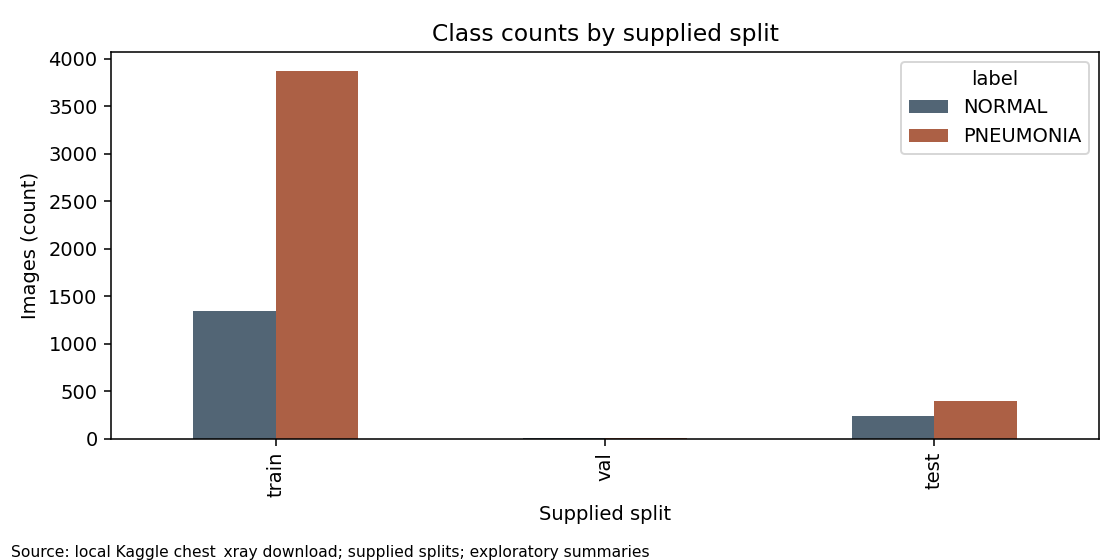

In [11]:
class_counts = images.label.value_counts()
display(pd.DataFrame({'images': class_counts, 'percent': 100*class_counts/len(images)}).round(2))
print('Pneumonia/normal ratio:', round(class_counts['PNEUMONIA']/class_counts['NORMAL'],2))
ax=counts.plot.bar(color=['#526575','#ac6045'],figsize=(8,4))
ax.set(title='Class counts by supplied split',xlabel='Supplied split',ylabel='Images (count)')
show_plot('eda_class_balance.png')

## 12. Summarize image brightness and contrast

Mean intensity describes average brightness; pixel standard deviation is a simple contrast proxy. These are image statistics, not confirmed disease markers.

In [12]:
stats_columns=['mean_intensity','std_intensity','dark_fraction','bright_fraction']
display(images.groupby('label')[stats_columns].agg(['mean','median','std','min','max']).round(3))
images.groupby(['split','label'])[stats_columns].describe().to_csv(OUTPUT/'results/eda_extended_statistics.csv')

mean_intensity                           ... bright_fraction                   
                    mean   median     std     min  ...          median    std  min    max
label                                              ...                                   
NORMAL           122.634  122.379  13.538  73.298  ...           0.001  0.004  0.0  0.092
PNEUMONIA        122.843  122.872  19.893  58.723  ...           0.000  0.001  0.0  0.043

[2 rows x 20 columns]

## 13. Plot the image-size distributions

Inspect width, height and aspect ratio. Aspect-preserving resizing avoids stretching anatomy.

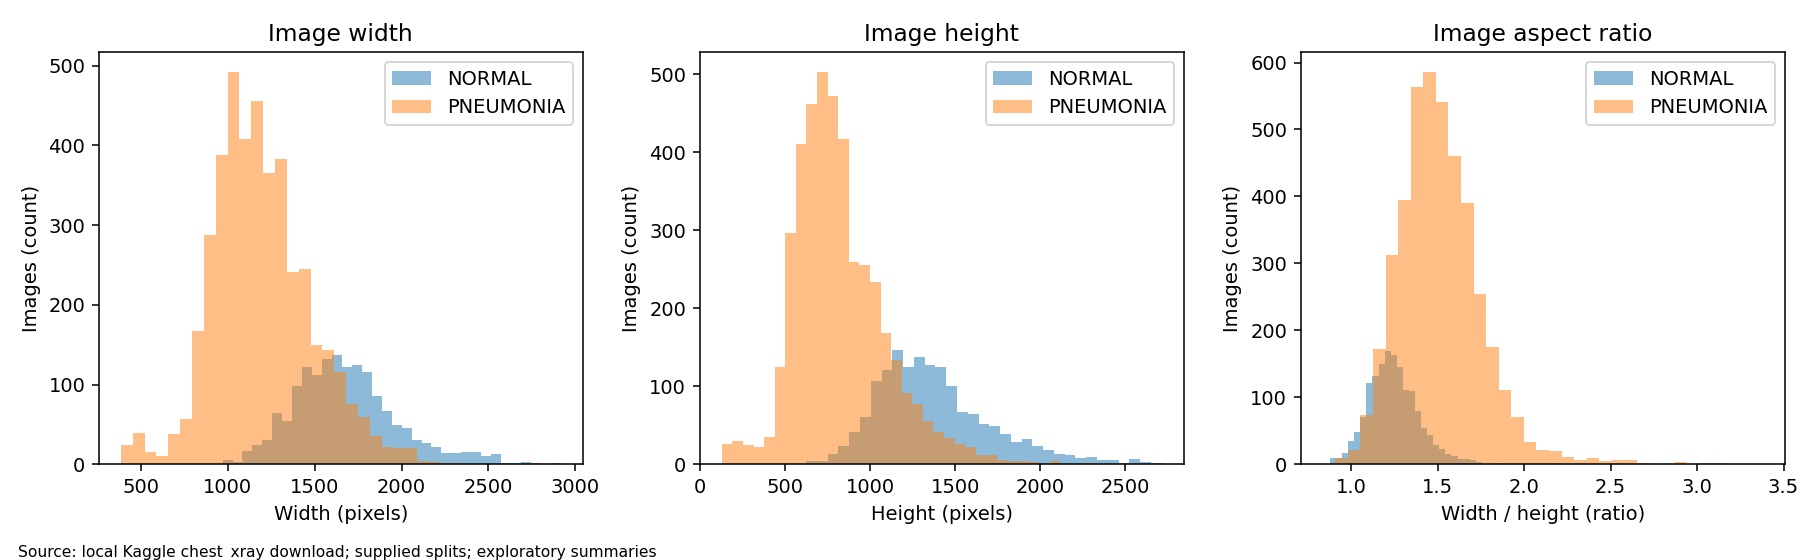

In [13]:
fig,axes=plt.subplots(1,3,figsize=(13,4))
for label in CLASSES:
    part=images[images.label==label]
    for ax,column in zip(axes[:2],['width','height']): ax.hist(part[column],bins=35,alpha=.5,label=label)
    axes[2].hist(part.width/part.height,bins=35,alpha=.5,label=label)
for ax,title,unit in zip(axes,['Image width','Image height','Image aspect ratio'],['Width (pixels)','Height (pixels)','Width / height (ratio)']):
    ax.set(title=title,xlabel=unit,ylabel='Images (count)'); ax.legend()
show_plot('eda_image_sizes.png')

## 14. Plot intensity distributions by class

Comparing distributions can reveal large brightness/contrast differences and possible preprocessing confounding. Overlap also explains why a single cutoff may be insufficient.

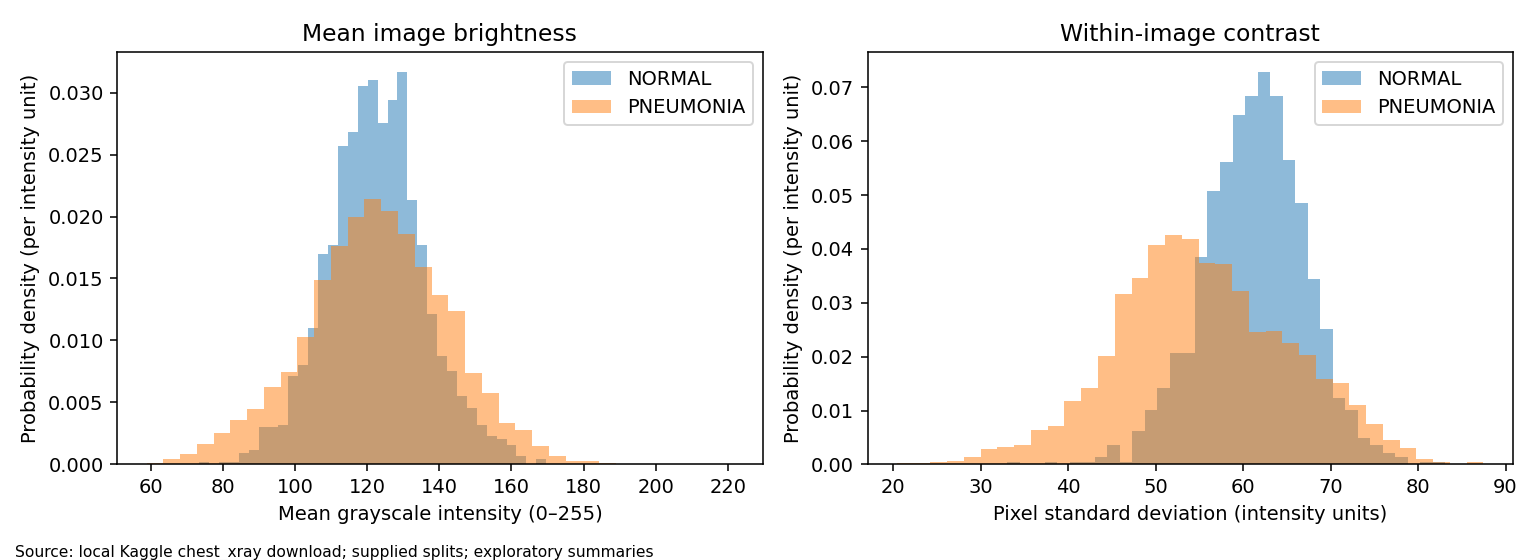

In [14]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label in CLASSES:
    part=images[images.label==label]
    axes[0].hist(part.mean_intensity,bins=35,alpha=.5,label=label,density=True)
    axes[1].hist(part.std_intensity,bins=35,alpha=.5,label=label,density=True)
for ax,title,xlabel in zip(axes,['Mean image brightness','Within-image contrast'],['Mean grayscale intensity (0–255)','Pixel standard deviation (intensity units)']):
    ax.set(title=title,xlabel=xlabel,ylabel='Probability density (per intensity unit)'); ax.legend()
show_plot('eda_intensity_distributions.png')

## 15. View representative radiographs

Use seeded development examples rather than choosing unusually clear images. Dataset labels are accepted annotations; visual examples do not verify them.

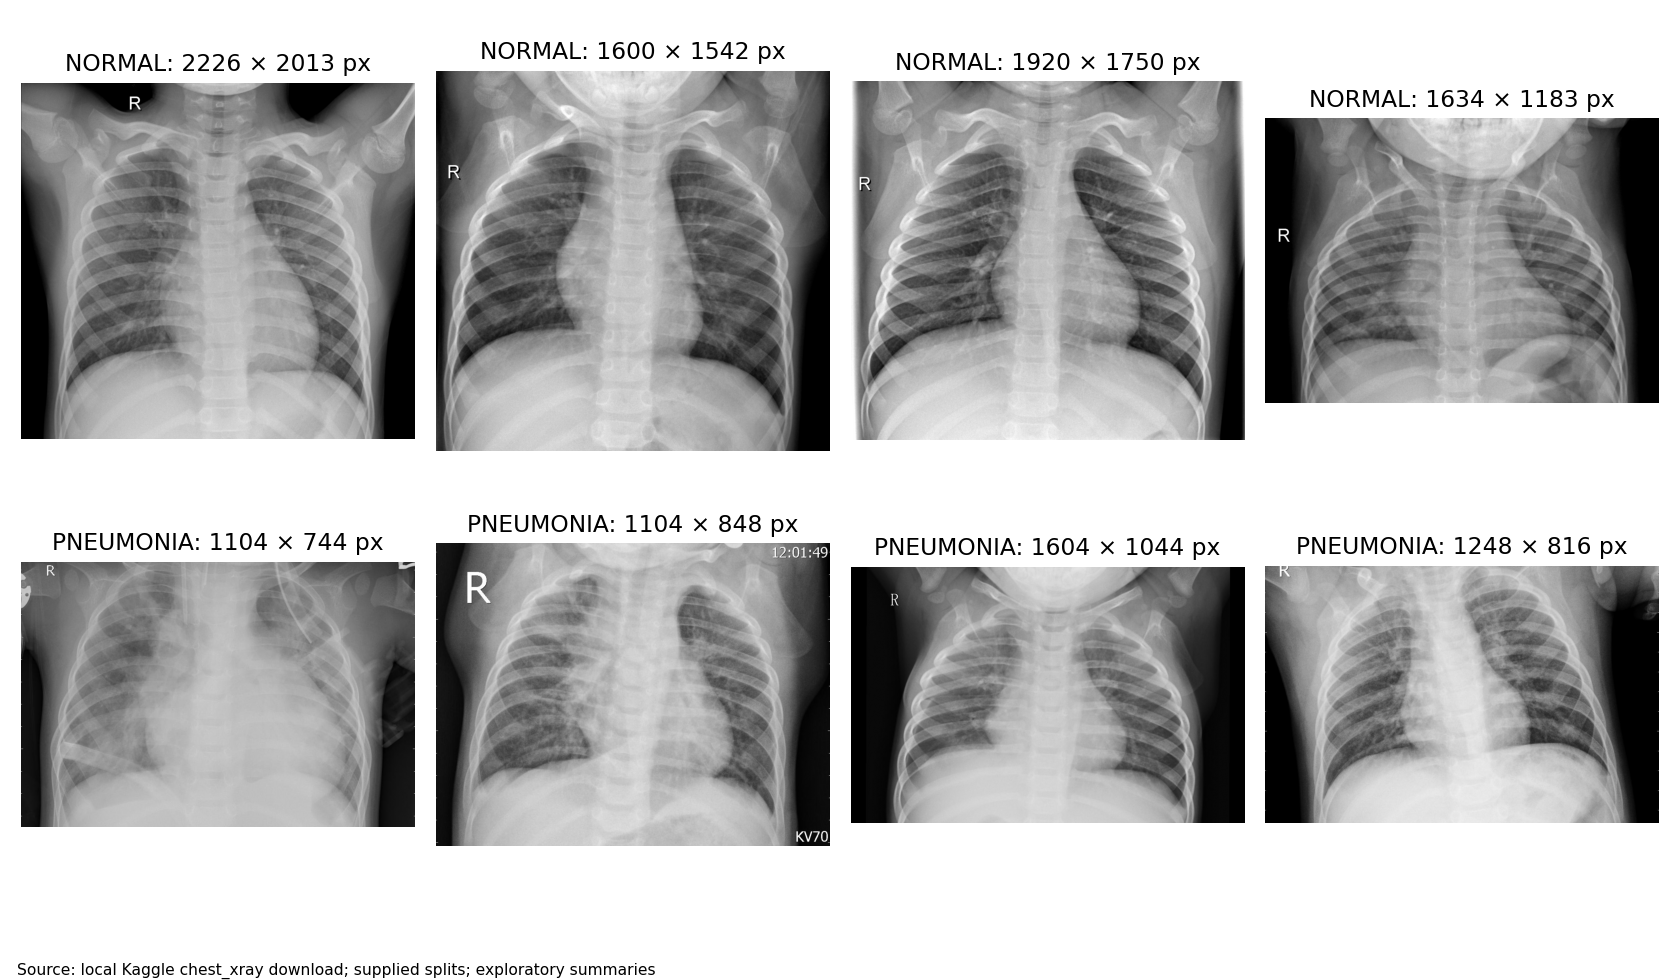

In [15]:
fig,axes=plt.subplots(2,4,figsize=(12,7))
for row,label in enumerate(CLASSES):
    examples=images[(images.label==label)&(images.partition=='development')].sample(4,random_state=SEED)
    for ax,item in zip(axes[row],examples.itertuples()):
        with Image.open(root/item.path) as im: ax.imshow(im.convert('L'),cmap='gray')
        ax.set_title(f'{label}: {item.width} × {item.height} px'); ax.axis('off')
show_plot('eda_representative_images.png')

## 16. Compare the supplied splits

The reference aggregates sales over dates. Here the relevant comparison is acquisition statistics across train/val/test, because there is no reliable clinical time axis. Summary differences are descriptive and do not tune the model.

mean_intensity  std_intensity    width   height
split label                                                     
test  NORMAL             124.07          60.17  1800.30  1369.09
      PNEUMONIA          119.23          55.97  1140.82   765.29
train NORMAL             122.38          61.44  1667.73  1381.43
      PNEUMONIA          123.20          55.34  1200.48   825.03
val   NORMAL             123.77          64.62  1479.50  1191.88
      PNEUMONIA          126.11          59.15  1217.00   814.00

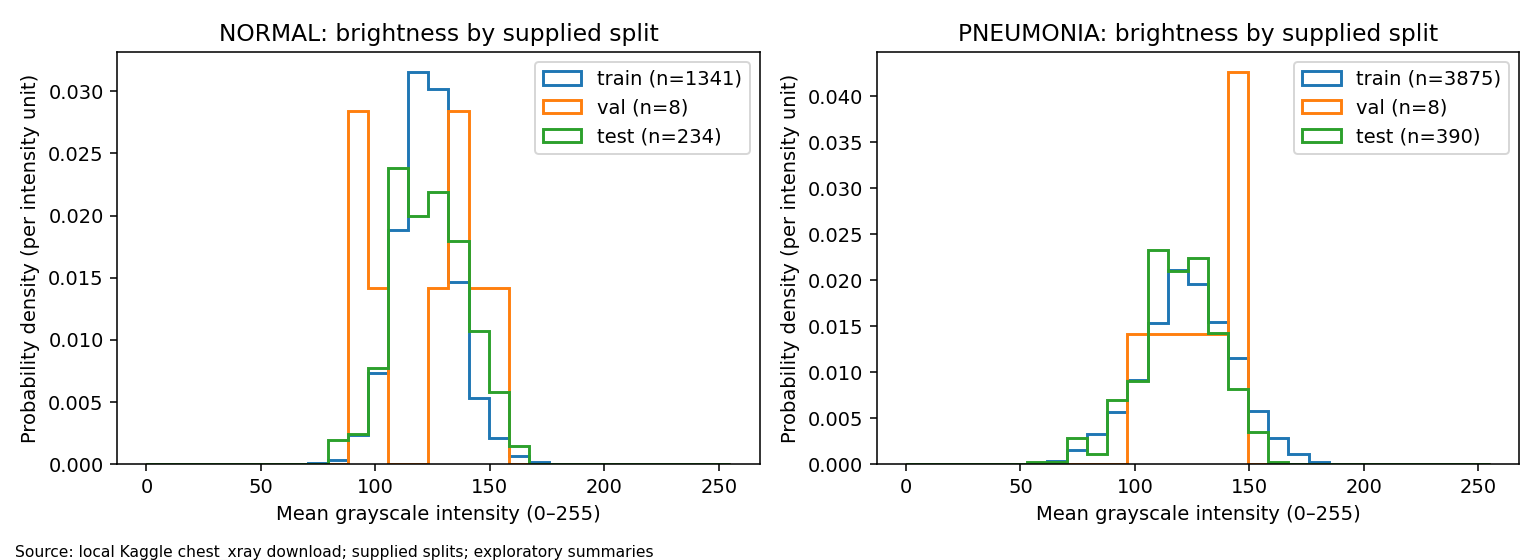

In [16]:
display(images.groupby(['split','label'])[['mean_intensity','std_intensity','width','height']].mean().round(2))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,label in zip(axes,CLASSES):
    for split in ['train','val','test']:
        values=images[(images.label==label)&(images.split==split)].mean_intensity
        ax.hist(values,bins=np.linspace(0,255,30),density=True,histtype='step',linewidth=1.5,label=f'{split} (n={len(values)})')
    ax.set(title=f'{label}: brightness by supplied split',xlabel='Mean grayscale intensity (0–255)',ylabel='Probability density (per intensity unit)'); ax.legend()
show_plot('eda_split_comparison.png')

## 17. Inspect dark and bright pixel fractions

Near-black and near-white pixel fractions flag exposure/border variation. We use no automatic quality cutoff, because arbitrary removal could bias the benchmark.

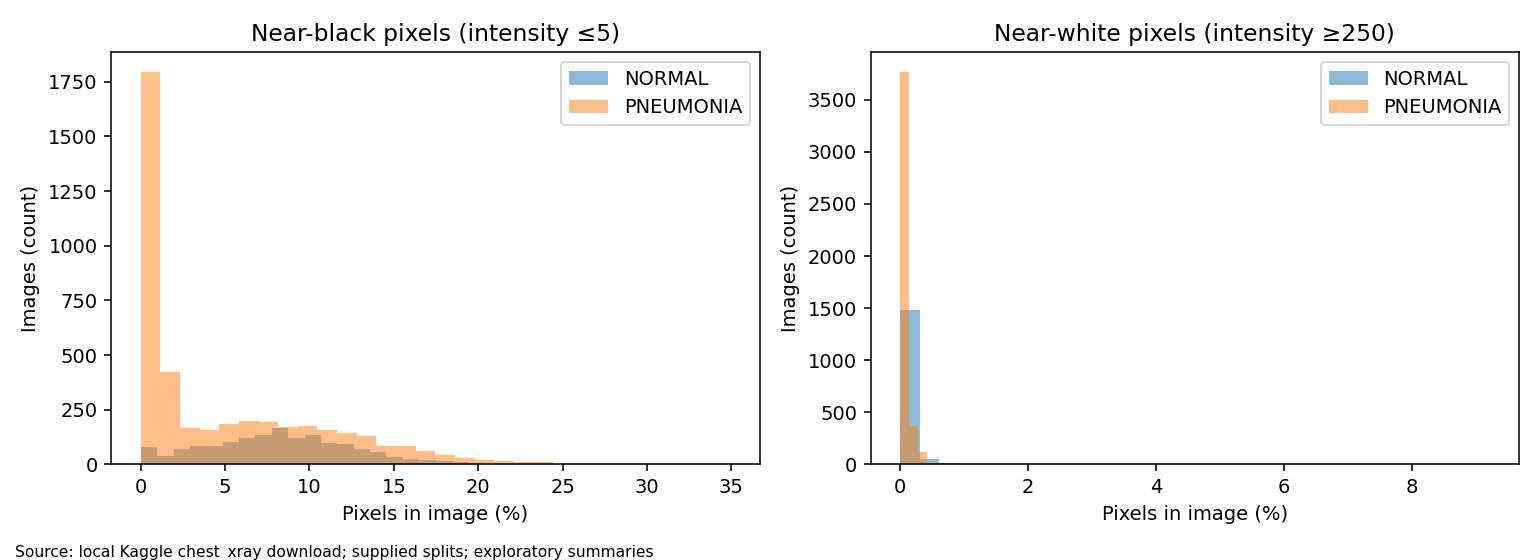

In [17]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label in CLASSES:
    part=images[images.label==label]
    axes[0].hist(100*part.dark_fraction,bins=30,alpha=.5,label=label)
    axes[1].hist(100*part.bright_fraction,bins=30,alpha=.5,label=label)
for ax,title in zip(axes,['Near-black pixels (intensity ≤5)','Near-white pixels (intensity ≥250)']):
    ax.set(title=title,xlabel='Pixels in image (%)',ylabel='Images (count)'); ax.legend()
show_plot('eda_exposure_proxies.png')

## 18. Check correlations among image statistics

Correlations reveal redundant summaries and possible acquisition relationships. Only retained development data is used here. Correlation does not imply causation.

,width,height,mean_intensity,std_intensity,dark_fraction,bright_fraction
width,1.00,0.93,0.08,0.49,0.36,0.11
height,0.93,1.00,0.11,0.40,0.26,0.11
mean_intensity,0.08,0.11,1.00,0.06,-0.25,0.12
std_intensity,0.49,0.40,0.06,1.00,0.74,0.19
dark_fraction,0.36,0.26,-0.25,0.74,1.00,0.10
bright_fraction,0.11,0.11,0.12,0.19,0.10,1.00


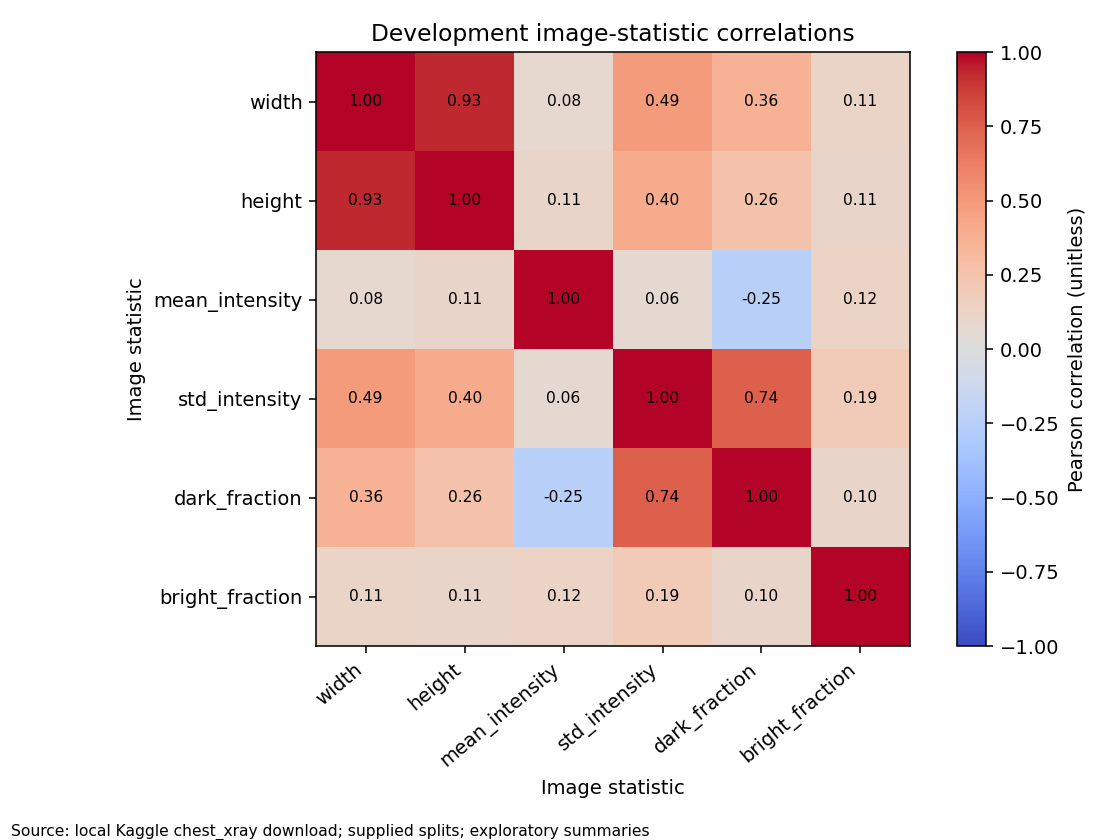

In [18]:
numeric=['width','height','mean_intensity','std_intensity','dark_fraction','bright_fraction']
corr=images.loc[images.partition=='development',numeric].corr()
display(corr.round(2))
fig,ax=plt.subplots(figsize=(8,6))
heat=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(numeric)),numeric,rotation=40,ha='right'); ax.set_yticks(range(len(numeric)),numeric)
for r in range(len(numeric)):
    for c in range(len(numeric)): ax.text(c,r,f'{corr.iloc[r,c]:.2f}',ha='center',va='center',fontsize=8)
ax.set(title='Development image-statistic correlations',xlabel='Image statistic',ylabel='Image statistic')
fig.colorbar(heat,ax=ax,label='Pearson correlation (unitless)')
show_plot('eda_correlations.png')

## 19. Save the cleaned analysis manifest

The audit keeps test-linked groups out of development and keeps one exact pixel copy. The small supplied validation set joins development. Raw images are never modified.

In [19]:
retained=images[images.partition!='excluded']
print('Exclusions:', audit_summary['exclusions'])
display(pd.crosstab(retained.partition,retained.label))
print('Saved:', PROCESSED_DIR/'manifest.csv')
summary={'readable_images':len(images),'corrupt_images':len(corrupt),'duplicate_images':int(images.duplicated('pixel_hash').sum()),'retained_images':len(retained)}
(OUTPUT/'results/eda_summary.json').write_text(json.dumps(summary,indent=2))

Exclusions: {'group_overlap_with_test': 457, 'exact_pixel_duplicate': 28}
Saved: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML/Datasets/processed/manifest.csv


label,NORMAL,PNEUMONIA
partition,,
development,1348,3405
test,231,387


## 20. EDA findings and next steps

The measured outputs show class imbalance, heterogeneous image dimensions, repeated images and cross-split filename group links. Inspect the plotted distributions for acquisition differences rather than assuming they represent disease effects. The 16-image validation set is too small for robust ranking.

Notebook 02 will normalize pixels, extract texture/intensity features and demonstrate training-only scaling. Notebook 03 will compare classical models with grouped CV and a reserved test. Patient proxies remain uncertain; true patient independence and external validity cannot be certified. No dates, weekdays or clinical demographic values are invented to imitate the retail dataset.

Data source: [Kaggle](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia/data). Dataset provenance: [Kermany et al. (2018)](https://doi.org/10.1016/j.cell.2018.02.010).